# Predicting p_challenge



In [136]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    log_loss,
    brier_score_loss,
    average_precision_score,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import RandomOverSampler, SMOTE
from xgboost import XGBClassifier

pd.set_option("display.max.columns", None)

## Preprocessing

In [137]:
data = pd.read_excel("../data-train.xlsx")
print(len(data))
data.head()

309063


,play_id,venue_id,balls,strikes,outs,inning,is_top_inning,pitcher_id,pitcher_hand,batter_id,batter_hand,catcher_id,umpire_id,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success,game_id
0,c0UdVTCjQ5SUsJ89,885087,0,0,1,8,True,AOFhIJmN,Right,aL98UBkP,Right,IML0r71A,xc8EcAsU,ball,4,1,89.460801,16.821696,7.641575,1.574127,4.983008,-4.832515,-0.680814,5.601144,-1.520694,1.963670,3.209,1.619,55,1,0,NaN,NaN,23411069
1,h8pmSGX80G2OMWkR,885087,2,2,1,3,True,AOFhIJmN,Right,4WzfJjoQ,Left,Lt1zY28i,yyLr2VlZ,called_strike,0,0,87.280420,4.356654,13.543660,1.629416,4.920186,-1.887169,-1.521324,5.629167,0.264480,1.491304,3.226,1.628,19,5,0,NaN,NaN,17660261
2,6n0nKEkw0o3e2Hyp,885087,0,0,1,9,True,AOFhIJmN,Right,434FhI32,Left,IML0r71A,2zPzWXe3,ball,11,6,88.743120,1.779116,13.102996,1.596064,5.016592,-2.066066,-1.694117,5.657749,-0.144320,1.486783,3.079,1.554,85,1,0,NaN,NaN,1275089
3,aAgwjqGrKTKOjn1f,491167,0,0,0,8,False,AOFhIJmN,Right,8IcFD5g6,Left,S9mCZLBI,vZTudVJV,ball,4,6,88.711556,3.831993,13.076229,1.495055,4.894893,-2.602191,-1.971373,5.599896,-0.577967,1.231735,3.410,1.721,69,1,0,NaN,NaN,11359429
4,mBsYKFCsq0hvdRba,885087,2,1,1,8,True,AOFhIJmN,Right,aL98UBkP,Right,IML0r71A,xc8EcAsU,ball,4,1,89.783730,15.221224,8.114938,1.498178,5.007579,-4.388744,-0.150483,5.619921,-1.312273,2.538484,3.209,1.619,55,4,0,NaN,NaN,23411069


In [138]:
metadata = ["play_id", "venue_id", "pitcher_id", "batter_id", "catcher_id", "umpire_id", "game_id"]
non_target_features = ["challenge_source", "is_success"]
X = data.drop(metadata + non_target_features, axis=1).dropna()
y = X.pop("is_challenge")
groups = data.loc[X.index, "game_id"]  # not a feature, only used to split by game

# relabel binary features
positive_values = {
    "is_top_inning": True,
    "pitcher_hand": "Right",
    "batter_hand": "Right",
    "pitch_result": "called_strike",
}
for f, positive in positive_values.items():
    X[f] = (X[f] == positive).astype("int64")

print(X.shape, "challenge rate:", round(y.mean(), 4))
X.head()

(308623, 24) challenge rate: 0.0269


,balls,strikes,outs,inning,is_top_inning,pitcher_hand,batter_hand,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa
0,0,0,1,8,1,1,1,0,4,1,89.460801,16.821696,7.641575,1.574127,4.983008,-4.832515,-0.680814,5.601144,-1.520694,1.963670,3.209,1.619,55,1
1,2,2,1,3,1,1,0,1,0,0,87.280420,4.356654,13.543660,1.629416,4.920186,-1.887169,-1.521324,5.629167,0.264480,1.491304,3.226,1.628,19,5
2,0,0,1,9,1,1,0,0,11,6,88.743120,1.779116,13.102996,1.596064,5.016592,-2.066066,-1.694117,5.657749,-0.144320,1.486783,3.079,1.554,85,1
3,0,0,0,8,0,1,0,0,4,6,88.711556,3.831993,13.076229,1.495055,4.894893,-2.602191,-1.971373,5.599896,-0.577967,1.231735,3.410,1.721,69,1
4,2,1,1,8,1,1,1,0,4,1,89.783730,15.221224,8.114938,1.498178,5.007579,-4.388744,-0.150483,5.619921,-1.312273,2.538484,3.209,1.619,55,4


# Model Evaluation Metrics

From above, we see that the baseline challenge rate is quite low, at around 2.7%. That is, if a model just guessed "no challenge" for all pitches, it would have an accuracy score of around 97.3%. Therefore we must consider other metrics to measure how well the model tells apart pitches that get challenged from those that don't. The metric we will be using are:

- log loss: measures how well the model's confidence matches the actual probability of a pitch getting challenged. For example, a called strike on the edge of the zone might only get challenged 20% of the time, so the model should only be 20% confident that it will be challenged (which is still way higher than the baseline 2.7%).
- AUROC/average precision: measures the probability of the model ranking a challenged pitch higher than a pitch that isn't challenged. Only measure how well the model sorts the data, not how confidently it sorts.
- mean_p: mean of p_challenge predicted by the model. should match the baseline rate of 2.7%.
- max_p: the max confidence the model gives that a pitch gets challenged.

We expect a good model to have:
- lowest log loss (well callibrated, meaning given probabilities match empirical probabilities)
- AUROC/average precision near 1 (distinguishes between challenged/not challenged pitches)
- mean_p near 2.7% (matches empirical baseline)
- max_p around 1 (can be confident)

# Caveats
- We expect the average precision to be fairly low, as two identical calls might not always be challenged the same. For example, a called ball middle middle (blown call) can only be challenged by catchers if they have challenges available. Moreover, some players are more confident in their judgement of strikes/balls, creating variance even on the same pitches.


## Train / test split by game

We will be using the test (validation) set to evaluate the models.

In [ ]:
# group shuffle split to split randomly by games, not individual pitches
# each distinct gameid is a different game
test_games = pd.read_excel("../data-test.xlsx", usecols=["game_id"])["game_id"]
print("games shared by data-train.xlsx and data-test.xlsx:", len(set(data["game_id"]) & set(test_games)))

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=67)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"train: {len(X_train)} pitches, {groups_train.nunique()} games, challenge rate {y_train.mean():.4f}")
print(f"test:  {len(X_test)} pitches, {groups.iloc[test_idx].nunique()} games, challenge rate {y_test.mean():.4f}")

games shared by data-train.xlsx and data-test.xlsx: 0
train: 246771 pitches, 1605 games, challenge rate 0.0271
test:  61852 pitches, 402 games, challenge rate 0.0262


In [140]:
results = {}
probas = {}

# removed confusion matrix + classification report as decision boundaries at fixed at 0.5
def evaluate(name, model):
    p = model.predict_proba(X_test)[:, 1]
    # y_pred = model.predict(X_test)
    # print(classification_report(y_test, y_pred, zero_division=0))
    results[name] = {
        "log_loss": log_loss(y_test, p),
        "auroc": roc_auc_score(y_test, p),
        "avg_precision": average_precision_score(y_test, p),
        "mean_p": p.mean(),
        "max_p": p.max(),
    }
    probas[name] = p
    print(pd.Series(results[name]).round(4).to_string())
    # ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    # plt.title(f"{name} Confusion Matrix")
    # plt.show()

## Baselines

In [141]:
# always predicts the training challenge rate of around 2.7%.
prior = DummyClassifier(strategy="prior").fit(X_train, y_train)
evaluate("Base rate", prior)

log_loss         0.1212
auroc            0.5000
avg_precision    0.0262
mean_p           0.0271
max_p            0.0271


In [142]:
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    clf = LogisticRegression(max_iter=1000, random_state=67).fit(X_train, y_train)
    evaluate("Logistic Regression", clf)

log_loss         0.1160
auroc            0.6484
avg_precision    0.0830
mean_p           0.0271
max_p            0.1906


# Observations

- As expected, our baselines have a mean_p of 2.7%, which matches the actual challenge rate in the dataset.
- Although the log losses look low, AUROC of 0.5 and 0.6 respectively show that the baseline models manage to barely (if at all) separate pitches that should be challenge from those what shouldn't.

## Decision Trees

In [143]:
dt = DecisionTreeClassifier(random_state=67).fit(X_train, y_train)
print("depth:", dt.get_depth(), "leaves:", dt.get_n_leaves())
evaluate("Decision Tree (default)", dt)

# a fully grown tree has pure leaves, so its probabilities are almost all exactly 0 or 1
print("share of predictions that are exactly 0 or 1:", np.isin(probas["Decision Tree (default)"], [0, 1]).mean().round(3))

depth: 42 leaves: 6620
log_loss         1.7098
auroc            0.5841
avg_precision    0.0527
mean_p           0.0315
max_p            1.0000
share of predictions that are exactly 0 or 1: 1.0


In [144]:
# tune tree size on log loss with 5-fold cross-validation over training games
cv = GroupKFold(n_splits=5)
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=67),
    param_grid={
        "max_depth": [4, 6, 8, 10, 12, 15, None],
        "min_samples_leaf": [1, 50, 200, 500, 1000],
    },
    scoring="neg_log_loss",
    cv=cv,
    n_jobs=-1,
)
dt_grid.fit(X_train, y_train, groups=groups_train)
print("best params:", dt_grid.best_params_, " CV log loss:", round(-dt_grid.best_score_, 4))

best params: {'max_depth': 15, 'min_samples_leaf': 1000}  CV log loss: 0.0943


base-rate CV log loss: 0.1246


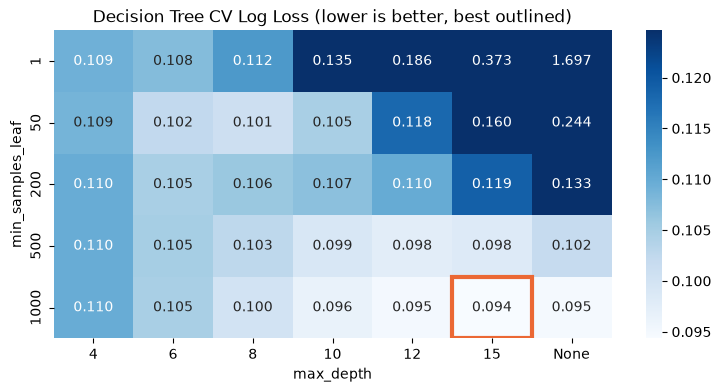

In [145]:
dt_cv = pd.DataFrame(dt_grid.cv_results_)
dt_cv["max_depth"] = dt_cv["param_max_depth"].fillna("None").astype(str)
dt_cv["log_loss"] = -dt_cv["mean_test_score"]
heat = dt_cv.pivot(index="param_min_samples_leaf", columns="max_depth", values="log_loss")
heat = heat[[str(d) for d in dt_grid.param_grid["max_depth"]]]

# base-rate log loss on the same folds; the colour scale tops out there,
# so the darkest cells do no better than always predicting the base rate
base_cv = -cross_val_score(
    DummyClassifier(strategy="prior"), X_train, y_train, groups=groups_train, cv=cv, scoring="neg_log_loss"
).mean()
print("base-rate CV log loss:", round(base_cv, 4))

plt.figure(figsize=(9, 4))
ax = sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", vmax=base_cv)
best_cell = (
    heat.columns.get_loc(str(dt_grid.best_params_["max_depth"])),
    heat.index.get_loc(dt_grid.best_params_["min_samples_leaf"]),
)
ax.add_patch(plt.Rectangle(best_cell, 1, 1, fill=False, edgecolor="#eb6834", lw=3))
plt.title("Decision Tree CV Log Loss (lower is better, best outlined)")
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.show()

In [146]:
best_dt = dt_grid.best_estimator_  # refit on all training games with the best params
print("depth:", best_dt.get_depth(), "leaves:", best_dt.get_n_leaves())
evaluate("Decision Tree (tuned)", best_dt)

depth: 15 leaves: 117
log_loss         0.0906
auroc            0.9005
avg_precision    0.1858
mean_p           0.0271
max_p            0.3128


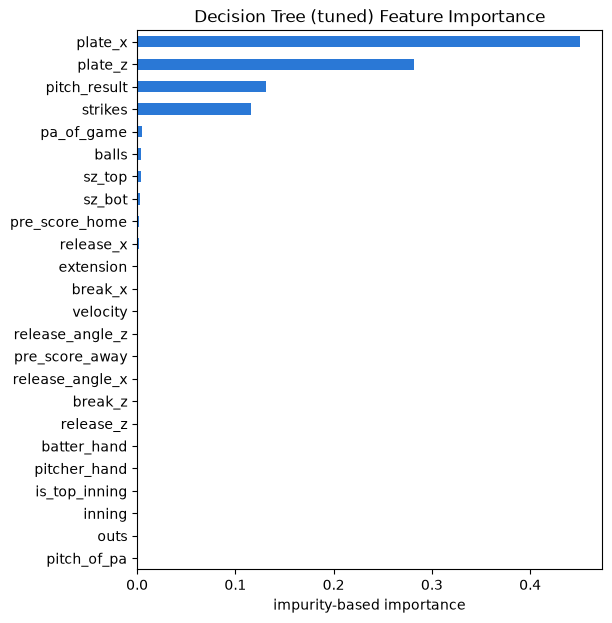

In [147]:
pd.Series(best_dt.feature_importances_, index=X.columns).sort_values().plot.barh(figsize=(6, 7), color="#2a78d6")
plt.title("Decision Tree (tuned) Feature Importance")
plt.xlabel("impurity-based importance")
plt.show()

### Observations
As expected, whether a pitch gets challenged or not depends mostly on pitch location, followed by what call was made by the umpire, and the strike count.

This makes sense as:
- If a pitch is way out of the zone or middle middle, umpires barely blow these calls, hence players rarely challenge.
- If a pitch is not in favour of one side and the pitch is close, they challenge it.
- If the count is full, both sides want to get the call they want; pitching team wants an out, hitter wants a walk.

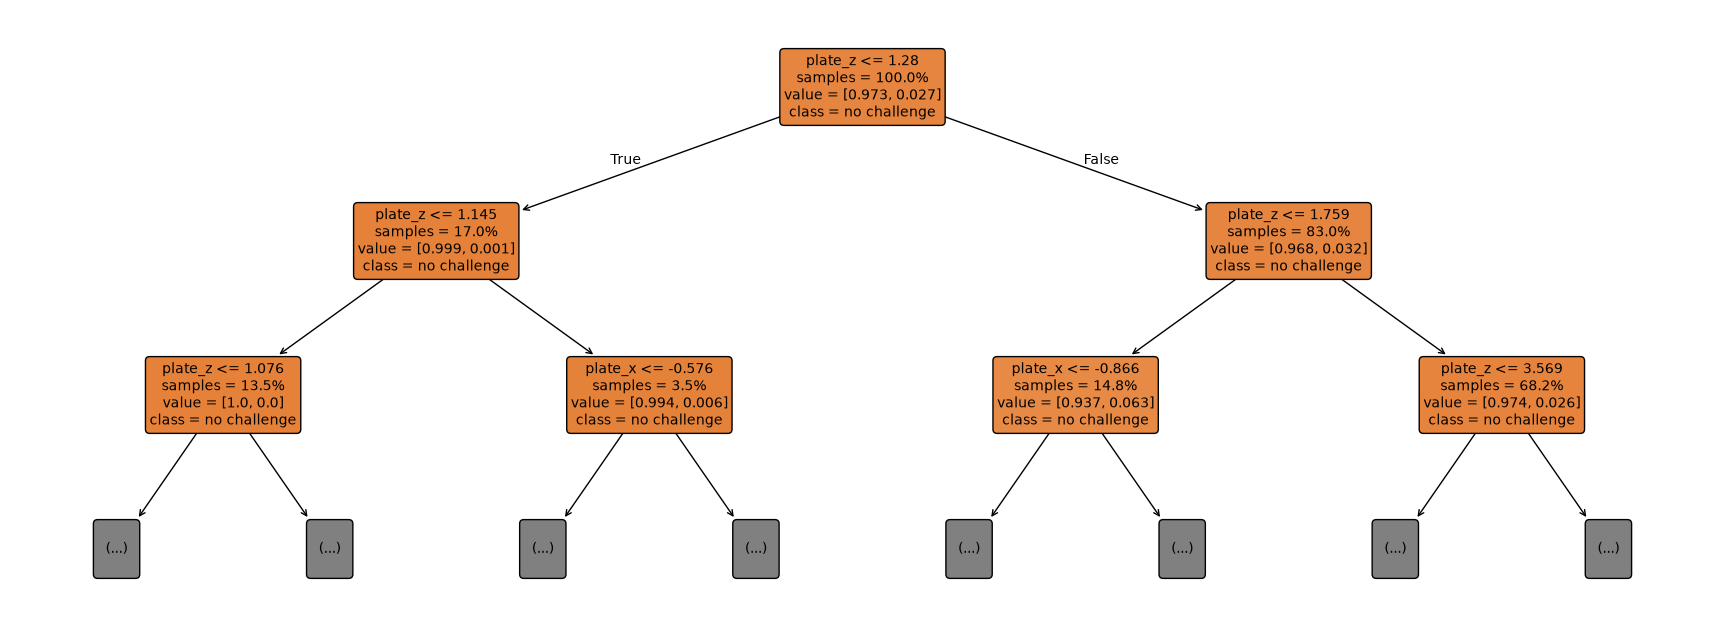

In [148]:
# first three levels of the tuned tree (value = share of [no challenge, challenge] in the node)
plt.figure(figsize=(22, 8))
plot_tree(
    best_dt,
    max_depth=2,
    feature_names=X.columns.tolist(),
    class_names=["no challenge", "challenge"],
    filled=True,
    impurity=False,
    proportion=True,
    rounded=True,
    fontsize=10,
)
plt.show()

# Observations
- As expected, most branches are decided by pitch location.

## Random forest

In [149]:
rf = RandomForestClassifier(n_jobs=-1, random_state=67).fit(X_train, y_train)
evaluate("Random Forest (default)", rf)

log_loss         0.0979
auroc            0.9003
avg_precision    0.1994
mean_p           0.0307
max_p            0.5600


In [150]:
# tune leaf size and features per split on log loss over training games.
# slowest cell (~6 min): 3 folds instead of 5, and max_samples=0.5 (each tree is grown on half the rows)
rf_grid = GridSearchCV(
    RandomForestClassifier(max_samples=0.5, n_jobs=-1, random_state=67),
    param_grid={
        "min_samples_leaf": [10, 50, 200],
        "max_features": ["sqrt", 0.5],
    },
    scoring="neg_log_loss",
    cv=GroupKFold(n_splits=3),
)
rf_grid.fit(X_train, y_train, groups=groups_train)
print("best params:", rf_grid.best_params_, " CV log loss:", round(-rf_grid.best_score_, 4))

rf_cv = pd.DataFrame(rf_grid.cv_results_)
rf_cv["cv_log_loss"] = -rf_cv["mean_test_score"]
rf_cv[["param_min_samples_leaf", "param_max_features", "cv_log_loss", "std_test_score", "mean_fit_time"]].sort_values("cv_log_loss").round(4)

best params: {'max_features': 0.5, 'min_samples_leaf': 50}  CV log loss: 0.0836


,param_min_samples_leaf,param_max_features,cv_log_loss,std_test_score,mean_fit_time
4,50,0.5,0.0836,0.0006,26.1045
3,10,0.5,0.0859,0.0009,29.6645
5,200,0.5,0.0865,0.0008,23.1929
0,10,sqrt,0.0914,0.0005,11.3705
1,50,sqrt,0.0946,0.0002,9.6254
2,200,sqrt,0.0992,0.0006,9.7384


In [151]:
best_rf = rf_grid.best_estimator_
evaluate("Random Forest (tuned)", best_rf)

log_loss         0.0807
auroc            0.9299
avg_precision    0.2624
mean_p           0.0274
max_p            0.4500


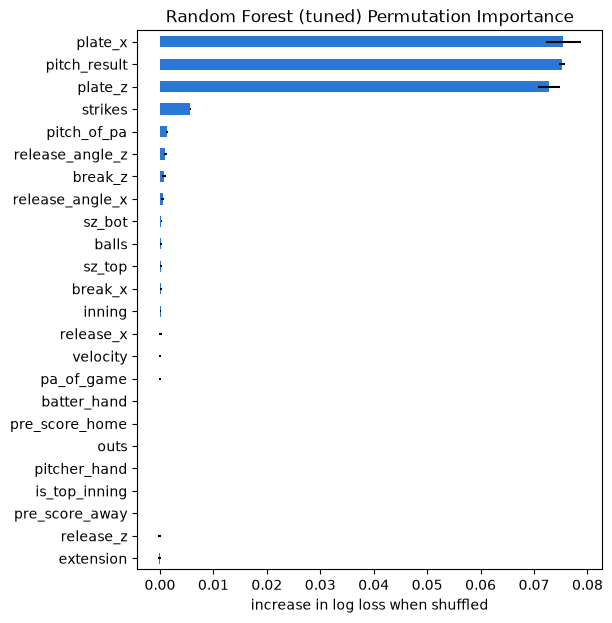

In [152]:
# permutation importance on the held-out games: how much worse log loss gets when a feature is shuffled
perm = permutation_importance(best_rf, X_test, y_test, scoring="neg_log_loss", n_repeats=5, random_state=67)
perm_importance = pd.DataFrame(
    {"mean": perm.importances_mean, "std": perm.importances_std}, index=X.columns
).sort_values("mean")

perm_importance["mean"].plot.barh(xerr=perm_importance["std"], figsize=(6, 7), color="#2a78d6")
plt.title("Random Forest (tuned) Permutation Importance")
plt.xlabel("increase in log loss when shuffled")
plt.show()

### Observations
- Like decision trees, the main deciding factor is pitch location. However, we also see that the model evalues strikes as being less important and the call being as important as location. RandomForest does beat our tuned decision tree in every metric, suggesting the decision tree was overfitting.

## XGBoost

In [153]:
xgb = XGBClassifier(random_state=67, n_jobs=-1).fit(X_train, y_train)
evaluate("XGBoost (default)", xgb)

log_loss         0.0813
auroc            0.9269
avg_precision    0.2375
mean_p           0.0263
max_p            0.9827


In [154]:
# boosted trees: tune tree depth, step size and number of trees on log loss,
# with the same 5-fold cross-validation over training games as the decision tree
xgb_grid = GridSearchCV(
    XGBClassifier(random_state=67, n_jobs=-1),
    param_grid={
        "max_depth": [3, 5, 7],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [200, 500],
    },
    scoring="neg_log_loss",
    cv=cv,
)
xgb_grid.fit(X_train, y_train, groups=groups_train)
print("best params:", xgb_grid.best_params_, " CV log loss:", round(-xgb_grid.best_score_, 4))

xgb_cv = pd.DataFrame(xgb_grid.cv_results_)
xgb_cv["cv_log_loss"] = -xgb_cv["mean_test_score"]
xgb_cv[["param_max_depth", "param_learning_rate", "param_n_estimators", "cv_log_loss", "std_test_score", "mean_fit_time"]].sort_values("cv_log_loss").round(4)

best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 500}  CV log loss: 0.0823


,param_max_depth,param_learning_rate,param_n_estimators,cv_log_loss,std_test_score,mean_fit_time
3,5,0.05,500,0.0823,0.0010,5.7333
8,5,0.10,200,0.0825,0.0009,2.0125
5,7,0.05,500,0.0826,0.0011,6.3644
10,7,0.10,200,0.0827,0.0010,3.5624
4,7,0.05,200,0.0827,0.0011,2.7624
7,3,0.10,500,0.0828,0.0010,3.1614
9,5,0.10,500,0.0829,0.0010,4.7828
2,5,0.05,200,0.0838,0.0010,1.9713
1,3,0.05,500,0.0850,0.0009,3.3222
6,3,0.10,200,0.0856,0.0011,1.8850


In [155]:
best_xgb = xgb_grid.best_estimator_
evaluate("XGBoost (tuned)", best_xgb)

log_loss         0.0791
auroc            0.9317
avg_precision    0.2614
mean_p           0.0268
max_p            0.8352


In [156]:
import json

# export the tuned XGBoost settings, so the model can be rebuilt later without rerunning the grid search:
#   XGBClassifier(**json.load(open("xgb_params_p_challenge.json"))).fit(X_train, y_train)
xgb_params = {k: v for k, v in best_xgb.get_params().items()
              if v is not None and not (isinstance(v, float) and np.isnan(v))}  # drop settings left at their defaults
with open("xgb_params_p_challenge.json", "w") as f:
    json.dump(xgb_params, f, indent=2)
xgb_params

{'objective': 'binary:logistic',
 'enable_categorical': True,
 'learning_rate': 0.05,
 'max_depth': 5,
 'n_estimators': 500,
 'n_jobs': -1,
 'random_state': 67}

# Observations
- XGBoost was our best model by far, beating out the previous models tried in most metrics, with emphasis on log loss and AUROC.

## Oversampling

In [157]:
ros = RandomOverSampler(random_state=67)
smote = SMOTE(random_state=67)
X_resampled, y_resampled = ros.fit_resample(X_train, y_train)
X_smote, y_smote = smote.fit_resample(X_train, y_train)

print(y_resampled.value_counts(), y_smote.value_counts())

is_challenge
0    240075
1    240075
Name: count, dtype: int64 is_challenge
0    240075
1    240075
Name: count, dtype: int64


In [158]:
# clone = same settings as the tuned model, unfitted
dt_oversampled = clone(best_dt).fit(X_resampled, y_resampled)
evaluate("Decision Tree + oversampling", dt_oversampled)

log_loss         0.3753
auroc            0.9147
avg_precision    0.1941
mean_p           0.2208
max_p            0.9596


In [159]:
dt_smote = clone(best_dt).fit(X_smote, y_smote)
evaluate("Decision Tree + SMOTE", dt_smote)

log_loss         0.3197
auroc            0.8820
avg_precision    0.1779
mean_p           0.1969
max_p            0.9894


In [160]:
rf_oversampled = clone(best_rf).fit(X_resampled, y_resampled)
evaluate("Random Forest + oversampling", rf_oversampled)

log_loss         0.2423
auroc            0.9291
avg_precision    0.2558
mean_p           0.1675
max_p            0.9743


In [161]:
rf_smote = clone(best_rf).fit(X_smote, y_smote)
evaluate("Random Forest + SMOTE", rf_smote)

log_loss         0.2619
auroc            0.8962
avg_precision    0.1882
mean_p           0.1750
max_p            1.0000


# Observations
- We see that the oversampled models have much higher mean_p, which makes total sense, as by oversampling we literally inflated the empirical baseline.
- This is also reflected in higher log loss due to the training set having much higher priors compared to the validation set.

In [162]:
# undo the inflated base rate: the oversampled models were trained on a 50/50 mix, so rescale each
# prediction's odds from that training rate back to the real one (Bayes' rule: odds scale with the prior odds)
prior_real = y_train.mean()
trained_on = {
    "Decision Tree + oversampling": y_resampled.mean(),
    "Decision Tree + SMOTE": y_smote.mean(),
    "Random Forest + oversampling": y_resampled.mean(),
    "Random Forest + SMOTE": y_smote.mean(),
}

def undo_oversampling(p, prior_resampled):
    p = np.clip(p, 0, 1 - 1e-12)  # p = 1 would give infinite odds
    odds = p / (1 - p) * (prior_real / (1 - prior_real)) / (prior_resampled / (1 - prior_resampled))
    return odds / (1 + odds)

adjusted = {}
for name, prior_resampled in trained_on.items():
    p, p_adj = probas[name], undo_oversampling(probas[name], prior_resampled)
    adjusted[name] = {
        "log_loss": log_loss(y_test, p),
        "log_loss (adjusted)": log_loss(y_test, p_adj),
        "mean_p": p.mean(),
        "mean_p (adjusted)": p_adj.mean(),
        "max_p": p.max(),
        "max_p (adjusted)": p_adj.max(),
    }
print(f"training challenge rate {prior_real:.4f}, after resampling {y_resampled.mean():.2f}; "
      f"held-out challenge rate {y_test.mean():.4f}")
pd.DataFrame(adjusted).T.round(4)

training challenge rate 0.0271, after resampling 0.50; held-out challenge rate 0.0262


,log_loss,log_loss (adjusted),mean_p,mean_p (adjusted),max_p,max_p (adjusted)
Decision Tree + oversampling,0.3753,0.0875,0.2208,0.0271,0.9596,0.3985
Decision Tree + SMOTE,0.3197,0.0994,0.1969,0.0225,0.9894,0.7216
Random Forest + oversampling,0.2423,0.0863,0.1675,0.0134,0.9743,0.5138
Random Forest + SMOTE,0.2619,0.0948,0.1750,0.0158,1.0000,1.0000


# Observations
- Even adjusting the predicted probabilities for oversampling's scale, the log loss is still way higher than without oversampling.

# Comparison

In [163]:
summary = pd.DataFrame(results).T.sort_values("log_loss")
print("actual challenge rate in held-out games:", round(y_test.mean(), 4))
summary.round(4)

actual challenge rate in held-out games: 0.0262


,log_loss,auroc,avg_precision,mean_p,max_p
XGBoost (tuned),0.0791,0.9317,0.2614,0.0268,0.8352
Random Forest (tuned),0.0807,0.9299,0.2624,0.0274,0.4500
XGBoost (default),0.0813,0.9269,0.2375,0.0263,0.9827
Decision Tree (tuned),0.0906,0.9005,0.1858,0.0271,0.3128
Random Forest (default),0.0979,0.9003,0.1994,0.0307,0.5600
Logistic Regression,0.1160,0.6484,0.0830,0.0271,0.1906
Base rate,0.1212,0.5000,0.0262,0.0271,0.0271
Random Forest + oversampling,0.2423,0.9291,0.2558,0.1675,0.9743
Random Forest + SMOTE,0.2619,0.8962,0.1882,0.1750,1.0000
Decision Tree + SMOTE,0.3197,0.8820,0.1779,0.1969,0.9894


Since we are being graded on log loss, we take the model with the lowest log loss, which was tuned XGBoost.

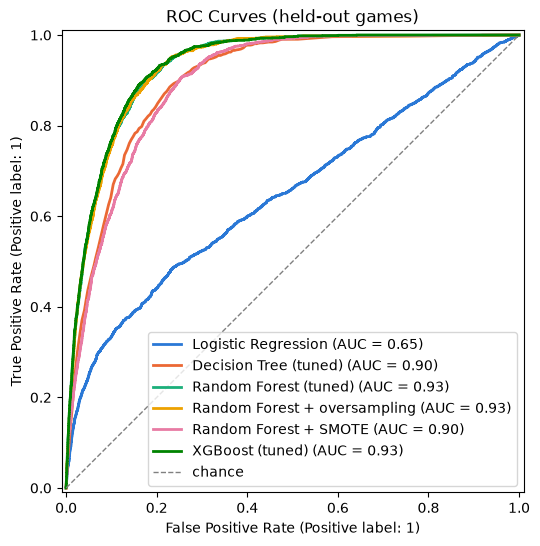

In [164]:
# one fixed colour per model across the plots below
colors = {
    "Logistic Regression": "#2a78d6",
    "Decision Tree (tuned)": "#eb6834",
    "Random Forest (tuned)": "#1baf7a",
    "Random Forest + oversampling": "#eda100",
    "Random Forest + SMOTE": "#e87ba4",
    "XGBoost (tuned)": "#008300",
}

fig, ax = plt.subplots(figsize=(6, 6))
for name in colors.keys():
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name, color=colors[name], lw=2, ax=ax)
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="gray", label="chance")
ax.legend(loc="lower right")
ax.set_title("ROC Curves (held-out games)")
plt.show()

Looking at the AUROC curve, we see that tuned XGBoost outperforms the rest of the models, though tuned Random Forest (also with oversampling) come close.

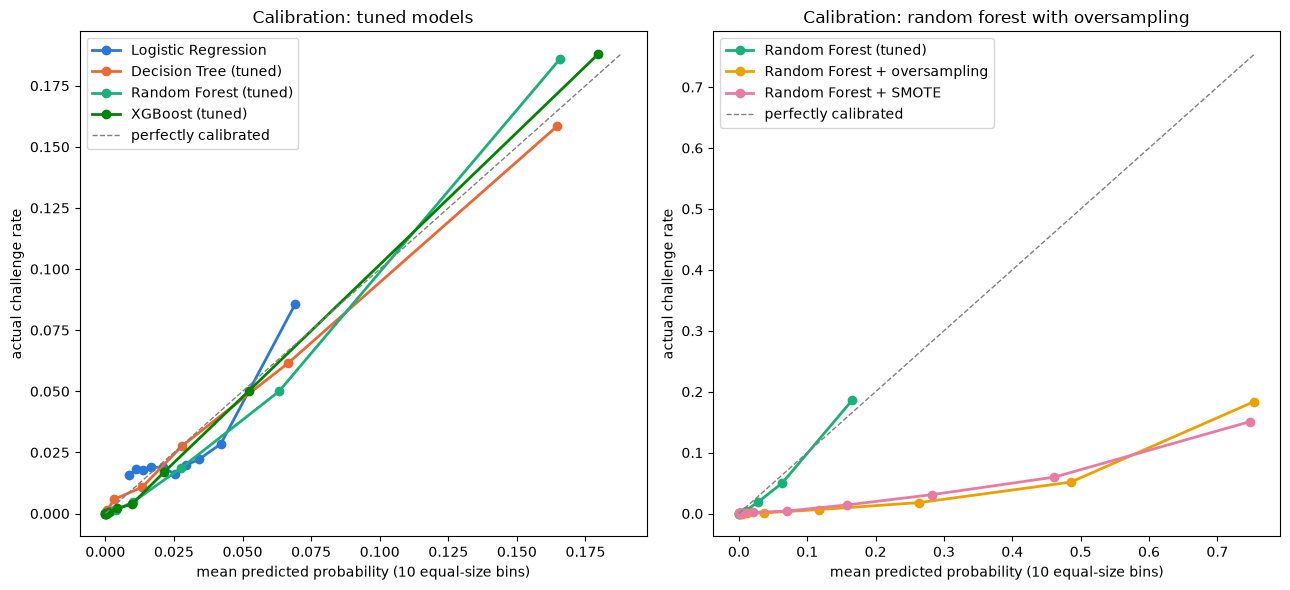

In [165]:
panels = {
    "Calibration: tuned models": ["Logistic Regression", "Decision Tree (tuned)", "Random Forest (tuned)", "XGBoost (tuned)"],
    "Calibration: random forest with oversampling": ["Random Forest (tuned)", "Random Forest + oversampling", "Random Forest + SMOTE"],
}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (title, names) in zip(axes, panels.items()):
    top = 0
    for name in names:
        prob_true, prob_pred = calibration_curve(y_test, probas[name], n_bins=10, strategy="quantile")
        ax.plot(prob_pred, prob_true, marker="o", lw=2, color=colors[name], label=name)
        top = max(top, prob_true.max(), prob_pred.max())
    ax.plot([0, top], [0, top], ls="--", lw=1, color="gray", label="perfectly calibrated")
    ax.set_title(title)
    ax.set_xlabel("mean predicted probability (10 equal-size bins)")
    ax.set_ylabel("actual challenge rate")
    ax.legend()
plt.tight_layout()
plt.show()

# Observations
- We also check how well the model's predicted probabilities align with the empirical probabilities. In the figure above, models that align more with the dotted line are better. For reasons given above, oversampled models perform significantly worse.

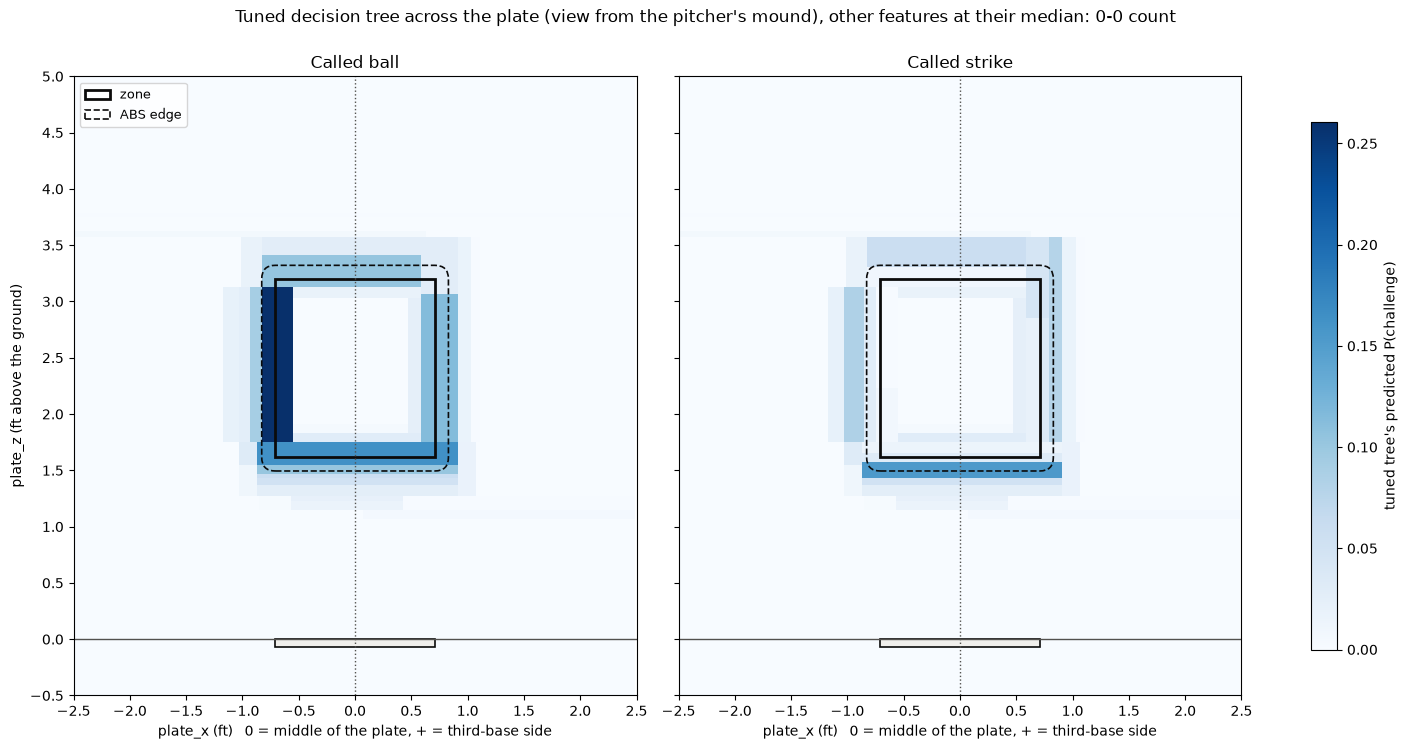

In [166]:
from matplotlib.patches import FancyBboxPatch, Rectangle

# tuned tree's predicted P(challenge) across the plate: only plate_x, plate_z and the call vary,
# every other feature is held at its median (change any of these, e.g. fixed["strikes"] = 2, to see the boundaries move)
fixed = X_train.median()
fixed["pitch_of_pa"] = fixed["balls"] + fixed["strikes"] + 1  # medians alone give a 0-0 count on pitch 2

xs = np.arange(-2.5, 2.5, 0.02)
zs = np.arange(-0.5, 5.0, 0.02)
gx, gz = np.meshgrid(xs, zs)
grid = pd.DataFrame(np.tile(fixed.to_numpy(), (gx.size, 1)), columns=X.columns)
grid["plate_x"], grid["plate_z"] = gx.ravel(), gz.ravel()

maps = {}
for call, value in [("Called ball", 0), ("Called strike", 1)]:
    grid["pitch_result"] = value
    maps[call] = best_dt.predict_proba(grid)[:, 1].reshape(gx.shape)

# strike zone from strike_zone.ipynb, using the same sz_top / sz_bot the tree is given here
PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)
INK, INK2 = "#0b0b0b", "#52514e"

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True, layout="constrained")
vmax = max(m.max() for m in maps.values())
for ax, (call, m) in zip(axes, maps.items()):
    mesh = ax.pcolormesh(xs, zs, m, cmap="Blues", vmin=0, vmax=vmax, shading="auto")
    ax.add_patch(Rectangle((-PLATE_HALF, fixed["sz_bot"]), 2 * PLATE_HALF, fixed["sz_top"] - fixed["sz_bot"],
                           fill=False, ec=INK, lw=2, label="zone"))
    ax.add_patch(FancyBboxPatch((-PLATE_HALF, fixed["sz_bot"]), 2 * PLATE_HALF, fixed["sz_top"] - fixed["sz_bot"],
                                boxstyle=f"round,pad={BALL_R},rounding_size={BALL_R}",
                                fill=False, ec=INK, lw=1.2, ls="--", label="ABS edge"))
    ax.axhline(0, color=INK2, lw=1)
    ax.add_patch(Rectangle((-PLATE_HALF, -0.07), 2 * PLATE_HALF, 0.07, fc="#f0efec", ec=INK, lw=1.2))
    ax.axvline(0, color=INK2, ls=":", lw=1)
    ax.set(title=call, xlim=(-2.5, 2.5), ylim=(-0.5, 5.0), aspect="equal",
           xlabel="plate_x (ft)   0 = middle of the plate, + = third-base side")
    ax.set_xticks(np.arange(-2.5, 2.51, 0.5))
    ax.set_yticks(np.arange(-0.5, 5.01, 0.5))
axes[0].set_ylabel("plate_z (ft above the ground)")
axes[0].legend(loc="upper left", fontsize=9)
fig.colorbar(mesh, ax=axes, shrink=0.75, label="tuned tree's predicted P(challenge)")
fig.suptitle(f"Tuned decision tree across the plate (view from the pitcher's mound), "
             f"other features at their median: {fixed['balls']:.0f}-{fixed['strikes']:.0f} count")
plt.show()

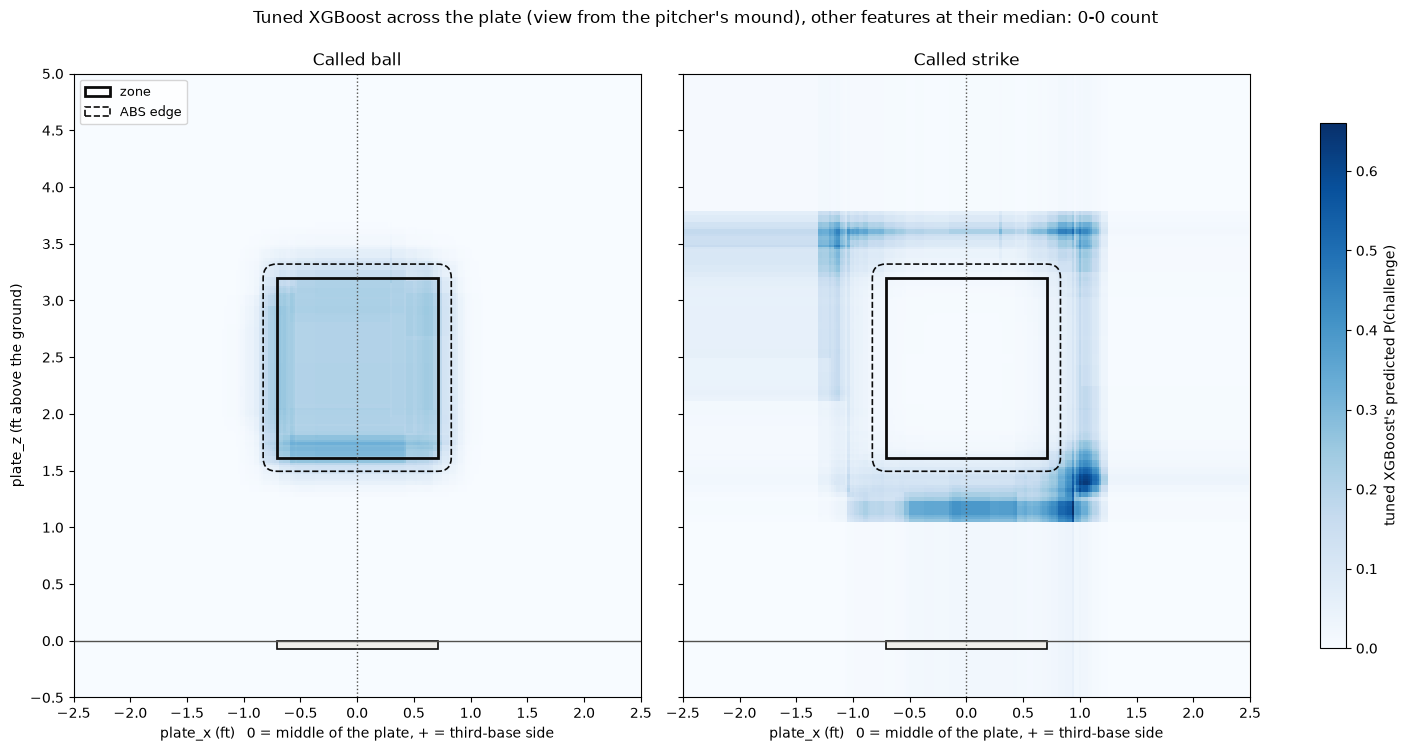

In [167]:
from matplotlib.patches import FancyBboxPatch, Rectangle

# the same slice as the tree's plot above, redrawn with tuned XGBoost: only plate_x, plate_z and the call vary,
# every other feature is held at its median (change any of these, e.g. fixed["strikes"] = 2, to see the boundaries move)
fixed = X_train.median()
fixed["pitch_of_pa"] = fixed["balls"] + fixed["strikes"] + 1  # medians alone give a 0-0 count on pitch 2

xs = np.arange(-2.5, 2.5, 0.02)
zs = np.arange(-0.5, 5.0, 0.02)
gx, gz = np.meshgrid(xs, zs)
grid = pd.DataFrame(np.tile(fixed.to_numpy(), (gx.size, 1)), columns=X.columns)
grid["plate_x"], grid["plate_z"] = gx.ravel(), gz.ravel()

xgb_maps = {}
for call, value in [("Called ball", 0), ("Called strike", 1)]:
    grid["pitch_result"] = value
    xgb_maps[call] = best_xgb.predict_proba(grid)[:, 1].reshape(gx.shape)

# strike zone from strike_zone.ipynb, using the same sz_top / sz_bot the model is given here
PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)
INK, INK2 = "#0b0b0b", "#52514e"

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True, layout="constrained")
vmax = max(m.max() for m in xgb_maps.values())
for ax, (call, m) in zip(axes, xgb_maps.items()):
    mesh = ax.pcolormesh(xs, zs, m, cmap="Blues", vmin=0, vmax=vmax, shading="auto")
    ax.add_patch(Rectangle((-PLATE_HALF, fixed["sz_bot"]), 2 * PLATE_HALF, fixed["sz_top"] - fixed["sz_bot"],
                           fill=False, ec=INK, lw=2, label="zone"))
    ax.add_patch(FancyBboxPatch((-PLATE_HALF, fixed["sz_bot"]), 2 * PLATE_HALF, fixed["sz_top"] - fixed["sz_bot"],
                                boxstyle=f"round,pad={BALL_R},rounding_size={BALL_R}",
                                fill=False, ec=INK, lw=1.2, ls="--", label="ABS edge"))
    ax.axhline(0, color=INK2, lw=1)
    ax.add_patch(Rectangle((-PLATE_HALF, -0.07), 2 * PLATE_HALF, 0.07, fc="#f0efec", ec=INK, lw=1.2))
    ax.axvline(0, color=INK2, ls=":", lw=1)
    ax.set(title=call, xlim=(-2.5, 2.5), ylim=(-0.5, 5.0), aspect="equal",
           xlabel="plate_x (ft)   0 = middle of the plate, + = third-base side")
    ax.set_xticks(np.arange(-2.5, 2.51, 0.5))
    ax.set_yticks(np.arange(-0.5, 5.01, 0.5))
axes[0].set_ylabel("plate_z (ft above the ground)")
axes[0].legend(loc="upper left", fontsize=9)
fig.colorbar(mesh, ax=axes, shrink=0.75, label="tuned XGBoost's predicted P(challenge)")
fig.suptitle(f"Tuned XGBoost across the plate (view from the pitcher's mound), "
             f"other features at their median: {fixed['balls']:.0f}-{fixed['strikes']:.0f} count")
plt.show()

# Observations
- In the two figures above (four diagrams), we see that XGboost has a more intuitive and general p_challenge heatmap compared to the decision tree's; for called balls, most likely challenges concentrate within the strikezone, while for called strikes, most likely challenges concentrate on the borders of the strike zone.
- We also see that umpires tend to call pitches below the zone, as well as inside and low (for a right handed hitter) strikes, which frequently get challenged by hitters.

In [168]:
import plotly.graph_objects as go
from IPython.display import HTML, display

# held-out pitches at their real locations, colored by the tuned XGBoost's predicted chance of a challenge.
# every challenged pitch is shown (large, outlined); unchallenged pitches are a random sample (small),
# since all ~60,000 would make the chart slow. click a legend entry to show/hide it, double-click to show only that one
held_out = data.loc[X_test.index].assign(
    p_challenge=best_xgb.predict_proba(X_test)[:, 1],
    challenged=y_test.to_numpy() == 1,
)
held_out["outcome"] = np.select([~held_out["challenged"], held_out["is_success"] == 1],
                                ["not challenged", "overturned"], "upheld")
held_out["status"] = np.where(
    held_out["challenged"],
    "challenged by the " + held_out["challenge_source"].str.replace("_", " ") + ", " + held_out["outcome"],
    "not challenged",
)
n_sample = 6000
shown = pd.concat([held_out[~held_out["challenged"]].sample(n_sample, random_state=67), held_out[held_out["challenged"]]])

PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)
INK, INK2 = "#0b0b0b", "#52514e"
sz_top, sz_bot = X_train["sz_top"].median(), X_train["sz_bot"].median()

def abs_edge_text(df):
    # signed distance from each pitch's own ABS edge: its batter's sz_top / sz_bot and the plate, plus the ball's
    # radius, with rounded corners like the dashed outline (a ball exactly on the edge counts as inside)
    dx = df["plate_x"].abs() - PLATE_HALF
    dz = np.maximum(df["plate_z"] - df["sz_top"], df["sz_bot"] - df["plate_z"])
    inches = ((np.hypot(dx.clip(lower=0), dz.clip(lower=0)) + np.minimum(np.maximum(dx, dz), 0) - BALL_R) * 12).round(1)
    return inches.abs().map("{:.1f} in ".format) + np.where(inches > 0, "outside", "inside")

shown = shown.assign(abs_edge=abs_edge_text(shown))

fig = go.Figure()
# unchallenged first, so the challenged pitches are drawn on top.
# upheld and overturned challenges are separate legend entries under each call, so either can be shown/hidden alone
for outcome, name, size, opacity, outline in [("not challenged", "not challenged (random sample)", 5, 0.6, 0),
                                              ("upheld", "challenged, upheld", 9, 0.95, 1),
                                              ("overturned", "challenged, overturned", 9, 0.95, 1)]:
    for call, group in [("ball", "Called ball"), ("called_strike", "Called strike")]:
        pts = shown[(shown["pitch_result"] == call) & (shown["outcome"] == outcome)]
        fig.add_trace(go.Scattergl(
            x=pts["plate_x"], y=pts["plate_z"], mode="markers",
            name=f"{name} ({len(pts):,})", legendgroup=group, legendgrouptitle_text=group,
            marker=dict(color=pts["p_challenge"], coloraxis="coloraxis", size=size, opacity=opacity,
                        line=dict(width=outline, color=INK)),
            customdata=np.stack([pts["play_id"], pts["p_challenge"].map("{:.3f}".format), pts["status"],
                                 pts["balls"].astype(str) + "-" + pts["strikes"].astype(str), pts["inning"], pts["batter_hand"],
                                 pts["abs_edge"], pts["sz_top"], pts["sz_bot"]], axis=1),
            hovertemplate=(f"<b>{group}</b>, %{{customdata[2]}}<br>predicted P(challenge) %{{customdata[1]}}"
                           "<br>count %{customdata[3]}, inning %{customdata[4]}, %{customdata[5]}-handed batter"
                           "<br>ABS edge (this batter's zone): %{customdata[6]}"
                           "<br>plate_x %{x:.2f} ft, plate_z %{y:.2f} ft<br>play_id %{customdata[0]}<extra></extra>"),
        ))

# zone for the median batter, and the ABS edge one ball radius outside it (WebGL lines, drawn above the points)
fig.add_trace(go.Scattergl(
    x=[-PLATE_HALF, PLATE_HALF, PLATE_HALF, -PLATE_HALF, -PLATE_HALF], y=[sz_bot, sz_bot, sz_top, sz_top, sz_bot],
    mode="lines", line=dict(color=INK, width=2.5), name="zone (median batter)",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
arc = np.linspace(0, np.pi / 2, 12)
corners = [(PLATE_HALF, sz_top, 0), (-PLATE_HALF, sz_top, np.pi / 2), (-PLATE_HALF, sz_bot, np.pi), (PLATE_HALF, sz_bot, 1.5 * np.pi)]
edge_x = np.concatenate([cx + BALL_R * np.cos(start + arc) for cx, _, start in corners])
edge_z = np.concatenate([cz + BALL_R * np.sin(start + arc) for _, cz, start in corners])
fig.add_trace(go.Scattergl(
    x=np.append(edge_x, edge_x[0]), y=np.append(edge_z, edge_z[0]),
    mode="lines", line=dict(color=INK, width=1.5, dash="dash"), name="ABS edge",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
fig.add_vline(x=0, line=dict(color=INK2, width=1, dash="dot"))
fig.add_annotation(x=2.15, y=0.3, text="right-handed<br>batter's side →", showarrow=False, xanchor="right", font=dict(color=INK2))
fig.add_annotation(x=-2.15, y=0.3, text="← left-handed<br>batter's side", showarrow=False, xanchor="left", font=dict(color=INK2))

fig.update_layout(
    title=dict(text="Held-out pitches: predicted chance of a challenge (view from the pitcher's mound)",
               subtitle=dict(text=f"Color = tuned XGBoost's predicted P(challenge); large outlined = actually challenged, "
                                  f"small = not challenged (random {n_sample:,} of {(~held_out['challenged']).sum():,})<br>"
                                  "Hover a pitch to see its batter's own zone (green)")),
    # light gray -> dark blue; the scale tops out at 0.5 so the low probabilities stay distinguishable
    coloraxis=dict(colorscale=[[0, "#d9d9d9"], [0.4, "#5598e7"], [1, "#0d366b"]], cmin=0, cmax=0.5,
                   colorbar=dict(title="predicted<br>P(challenge)")),
    width=950, height=970, plot_bgcolor="white", margin=dict(t=120),
    xaxis=dict(title="plate_x (ft)   0 = middle of the plate, + = third-base side",
               range=[-2.2, 2.2], dtick=0.5, gridcolor="#e1e0d9", zeroline=False),
    yaxis=dict(title="plate_z (ft above the ground)", range=[0, 4.8], dtick=0.5, gridcolor="#e1e0d9",
               zeroline=False, scaleanchor="x", scaleratio=1),
    legend=dict(groupclick="toggleitem", traceorder="grouped", orientation="h", y=-0.08),
)
# hovering a pitch draws its batter's own zone (solid) and ABS edge (dashed) in green; moving off removes them.
# a pitch's sz_top / sz_bot are the last two customdata entries
OWN_ZONE_ON_HOVER = """
const gd = document.getElementById('{plot_id}');
const base = (gd.layout.shapes || []).slice();
const PH = 17 / 24, R = 1.45 / 12, GREEN = '#008300';
function edgePath(top, bot) {
  const pts = [];
  for (const [cx, cz, a0] of [[PH, top, 0], [-PH, top, Math.PI / 2], [-PH, bot, Math.PI], [PH, bot, 1.5 * Math.PI]]) {
    for (let k = 0; k <= 8; k++) {
      const a = a0 + (Math.PI / 2) * k / 8;
      pts.push((cx + R * Math.cos(a)).toFixed(4) + ' ' + (cz + R * Math.sin(a)).toFixed(4));
    }
  }
  return 'M ' + pts.join(' L ') + ' Z';
}
gd.on('plotly_hover', ev => {
  const cd = ev.points[0].customdata;
  if (!cd) return;
  const top = parseFloat(cd[cd.length - 2]), bot = parseFloat(cd[cd.length - 1]);
  Plotly.relayout(gd, {shapes: base.concat([
    {type: 'rect', x0: -PH, x1: PH, y0: bot, y1: top, line: {color: GREEN, width: 2.5}, layer: 'above'},
    {type: 'path', path: edgePath(top, bot), line: {color: GREEN, width: 1.5, dash: 'dash'}, layer: 'above'},
  ])});
});
gd.on('plotly_unhover', () => Plotly.relayout(gd, {shapes: base}));
"""

display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, post_script=OWN_ZONE_ON_HOVER)))

# Limitations/Places for improvement
- There were number of pitches in the dataset I thought were anomalies. These are mainly: called balls clearly in the zone (even adjusting for batter height) that were challenged but upheld, and called strikes outside clearly outside the zone that were challenged but upheld.
- We cannot calculate challenges_available_for_home/away for data-test, meaning we cannot train models to take into account how many challenges they have available. This is arguably a crucial feature for predicting p_challenge, as a middle-middle ball call will never be challenged by a pitching team with no challenges left. It would have been great if we were given this as a feature in the dataset.
- We could also try an even more advanced model like MLPs.
